## Polynomial Regression on Boston Housing Dataset

**In this notebook we do a comparative study of Linear Regression and Polynomial Regression accuracy on the Boston Housing Dataset**

This data was originally a part of UCI Machine Learning Repository and has been removed now. This data also ships with the scikit-learn library. 
There are 506 samples and 13 feature variables in this data-set. The objective is to predict the value of prices of the house using the given features.

The description of all the features is given below:

  **CRIM**: Per capita crime rate by town

  **ZN**: Proportion of residential land zoned for lots over 25,000 sq. ft

  **INDUS**: Proportion of non-retail business acres per town

  **CHAS**: Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)

  **NOX**: Nitric oxide concentration (parts per 10 million)

  **RM**: Average number of rooms per dwelling

  **AGE**: Proportion of owner-occupied units built prior to 1940

  **DIS**: Weighted distances to five Boston employment centers

  **RAD**: Index of accessibility to radial highways

  **TAX**: Full-value property tax rate per $10,000

  **B**: 1000(Bk - 0.63)², where Bk is the proportion of [people of African American descent] by town

  **LSTAT**: Percentage of lower status of the population

  **MEDV**: Median value of owner-occupied homes in $1000s
  
  
  



I**mport the required Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Load the data into pandas dataframe . Load the Boston Housing DataSet from data/boston_house_prices.csv**

In [2]:
df = pd.read_csv("data/boston_house_prices.csv", header=1)
df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


**Data preprocessing**

Check for missing values in all the columns

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


**Data Visualization**

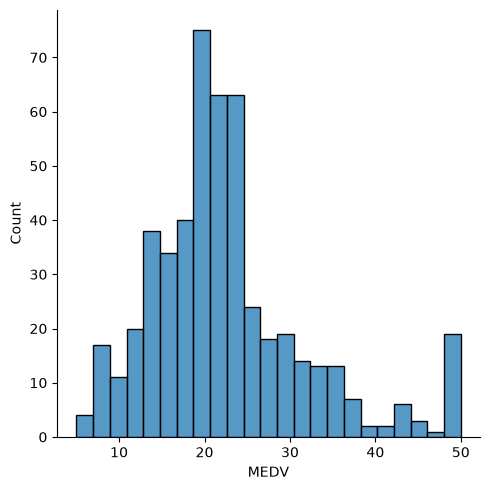

In [4]:
sns.displot(df['MEDV'])

**Correlation matrix**

Analyze the correlation matrix. Plot a heatmap

* From correlation plot: which are the columns that are more correlated with **MEDV**
* There are two features highly correlated. Identify them and drop one of them in order to avoid multi-colinearity

<Axes: >

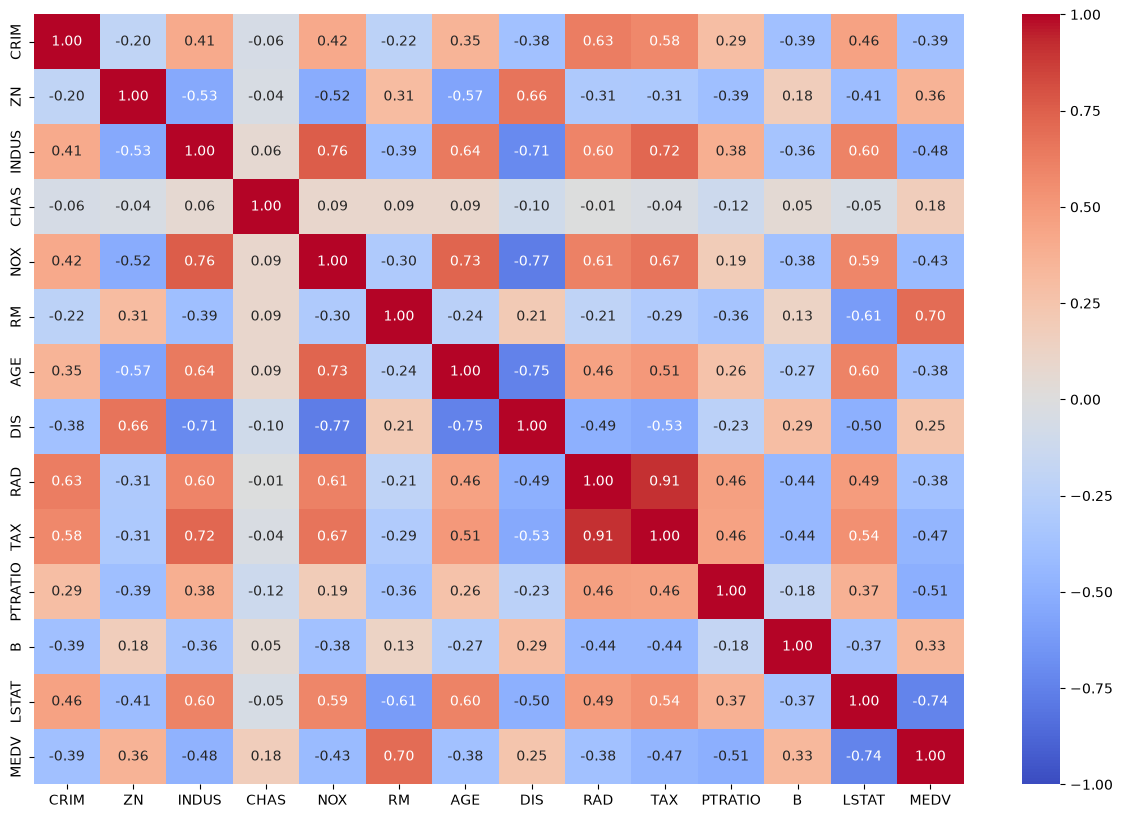

In [5]:
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", vmin=-1, fmt=".2f")

* LSTAT y RM son las variables más correladas con el target.

### Draw 2 scatter plots to see the relationship between **MEDV** and **LSTAT** and **RM**

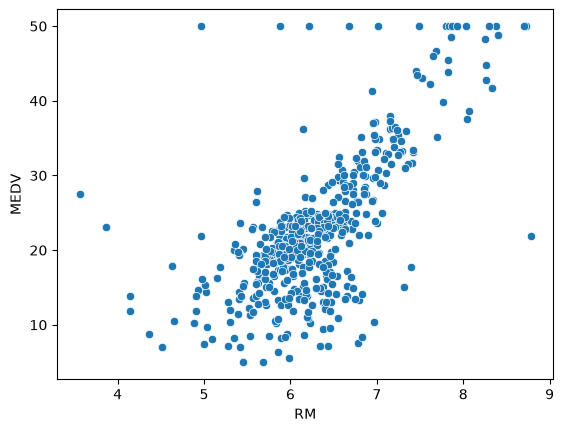

In [6]:
sns.scatterplot(x=df['RM'], y=df['MEDV']);

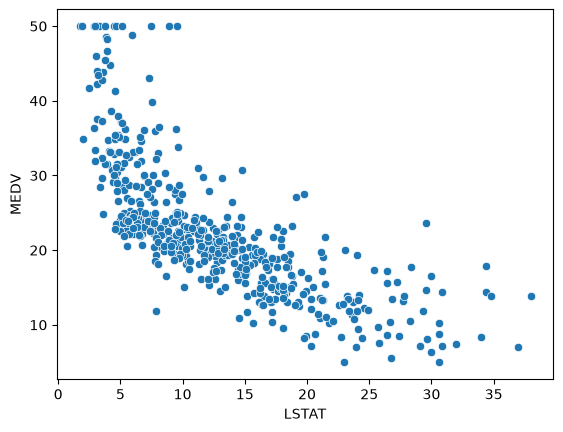

In [7]:
sns.scatterplot(x=df['LSTAT'], y=df['MEDV']);

**Prepare the data for training**
Create a dataframe X including **LSTAT** and **RM** columns.
Y should be a pandas series including target values **'MEDV'**


In [8]:
X = df[['RM', "LSTAT"]]
y = df['MEDV']

**Split the data into training and testing sets**

Splits the training and test data set in 80% : 20%. Assign random_state to any value. This ensures consistency. Print the sahes of the resulting objects

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=10)

In [10]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(404, 2)
(102, 2)
(404,)
(102,)


# **Linear Regression**

Build a linear regression model with sklearn LinearRegression.
We'll use Mean Squared error and R2 score to evaluate our model, so be sure to make the needed imports.

Import the necessary functions and train a LinearRegression model

In [11]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()

In [12]:
lin_reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 4.43,-0.68]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['RM','LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.145
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


**Evaluate the model performance in the training and testing sets**

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [14]:
y_pred_test = lin_reg.predict(X_test)

print("R2 score test", lin_reg.score(X_test, y_test))
print("MAE test", mean_absolute_error(y_test, y_pred_test))
print("MSE test", mean_squared_error(y_test, y_pred_test))

R2 score test 0.6041142735229119
MAE test 4.582645892343418
MSE test 41.40202341152383


In [15]:
y_pred_train = lin_reg.predict(X_train)

print("R2 score train", lin_reg.score(X_train, y_train))
print("MAE train", mean_absolute_error(y_train, y_pred_train))
print("MSE train", mean_squared_error(y_train, y_pred_train))

R2 score train 0.6363353379616082
MAE train 3.7980634226890113
MSE train 27.98794118547948


**Lets see the model performance visually. Let's plot y_test vs y_pred**

Plotting the y_test vs y_pred. Ideally should have been a straight line

<Axes: xlabel='MEDV'>

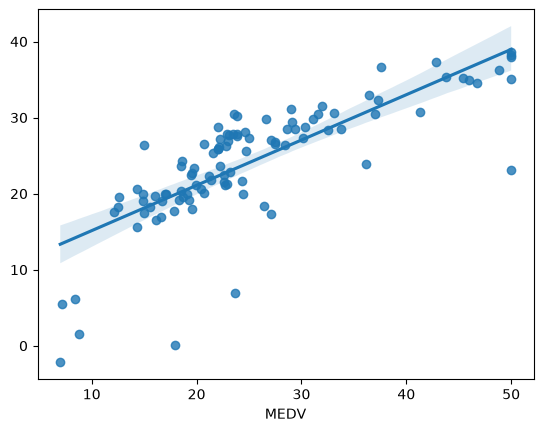

In [16]:
sns.regplot(x=y_test, y=y_pred_test)

# **Polynomial Regression**

We can see that **LSTAT** doesn't vary exactly in a linear way. Let's apply the Polynomial Regression with **degree 2** and test. 

To generate the higher order degrees, we use PolyniomialFeatures class from sklearn library. 

In [17]:
from sklearn.preprocessing import PolynomialFeatures

poly_reg = PolynomialFeatures(degree=2)
poly_reg.fit(X_train)
X_train_poly = poly_reg.transform(X_train)
X_test_poly = poly_reg.transform(X_test)

In [18]:
np.shape(X_train)

(404, 2)

In [19]:
np.shape(X_train_poly)

(404, 6)

In [20]:
pol_reg_2 = LinearRegression()
pol_reg_2.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[ 0. ,-15.49, 0.33, 1.74, -0.23, 0.01]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,61.73
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](6,)","[4691.47, 298.04, 149.51, 9.78, 0.98, 0. ]"


**Did the model improve using the Polynomial model?**

In [21]:
y_pred_test = pol_reg_2.predict(X_test_poly)

print("R2 score test", pol_reg_2.score(X_test_poly, y_test))
print("MAE test", mean_absolute_error(y_test, y_pred_test))
print("MSE test", mean_squared_error(y_test, y_pred_test))

R2 score test 0.7485007375000425
MAE test 3.542240876057965
MSE test 26.301979732039783


In [22]:
y_pred_train = pol_reg_2.predict(X_train_poly)

print("R2 score train", pol_reg_2.score(X_train_poly, y_train))
print("MAE train", mean_absolute_error(y_train, y_pred_train))
print("MSE train", mean_squared_error(y_train, y_pred_train))

R2 score train 0.7526744600340032
MAE train 3.0194990832234576
MSE train 19.034383564891193


**Did the model improve using the Polynomial model with degree 3? Or more?**

In [23]:
poly_reg = PolynomialFeatures(degree=3)
poly_reg.fit(X_train)
X_train_poly = poly_reg.transform(X_train)
X_test_poly = poly_reg.transform(X_test)

pol_reg_3 = LinearRegression()
pol_reg_3.fit(X_train_poly, y_train)

y_pred_test = pol_reg_3.predict(X_test_poly)

print("R2 score test", pol_reg_3.score(X_test_poly, y_test))
print("MAE test", mean_absolute_error(y_test, y_pred_test))
print("MSE test", mean_squared_error(y_test, y_pred_test))

y_pred_train = pol_reg_3.predict(X_train_poly)

print("R2 score train", pol_reg_3.score(X_train_poly, y_train))
print("MAE train", mean_absolute_error(y_train, y_pred_train))
print("MSE train", mean_squared_error(y_train, y_pred_train))

R2 score test 0.7504651949496077
MAE test 3.542002179068937
MSE test 26.096535312404843
R2 score train 0.7688165765778612
MAE train 2.9082028317118205
MSE train 17.792072569078908


In [24]:
np.shape(X_train_poly)

(404, 10)

In [25]:
poly_reg = PolynomialFeatures(degree=4)
poly_reg.fit(X_train)
X_train_poly = poly_reg.transform(X_train)
X_test_poly = poly_reg.transform(X_test)

pol_reg_4 = LinearRegression()
pol_reg_4.fit(X_train_poly, y_train)

y_pred_test = pol_reg_4.predict(X_test_poly)

print("R2 score test", pol_reg_4.score(X_test_poly, y_test))
print("MAE test", mean_absolute_error(y_test, y_pred_test))
print("MSE test", mean_squared_error(y_test, y_pred_test))

y_pred_train = pol_reg_4.predict(X_train_poly)

print("R2 score train", pol_reg_4.score(X_train_poly, y_train))
print("MAE train", mean_absolute_error(y_train, y_pred_train))
print("MSE train", mean_squared_error(y_train, y_pred_train))

R2 score test 0.7345229189206548
MAE test 3.6911491033876436
MSE test 27.76379038436028
R2 score train 0.7660797595733985
MAE train 2.942026494524759
MSE train 18.00270032962891


In [26]:
np.shape(X_train_poly)

(404, 15)

In [211]:
#rm = float(input("Introduce la variable de RM"))
#lstat = float(input("Introduce la variable de LSTAT"))

#pol_reg_2.predict(poly_reg.transform([[rm, lstat]]))

In [27]:
from sklearn.model_selection import cross_val_score

In [28]:
results_cv = cross_val_score(lin_reg, X, y, scoring="neg_mean_absolute_error", cv=10)
print(results_cv)
print(results_cv.mean())
print(results_cv.std())

[-2.74282364 -2.66486168 -2.89248316 -5.15153202 -3.9402028  -4.64564316
 -3.82923301 -8.69643448 -6.53638215 -2.94554412]
-4.404514022690067
1.8528516111956599


In [29]:
poly_reg = PolynomialFeatures(degree=2)
poly_reg.fit(X)
X_poly = poly_reg.transform(X)

results_cv = cross_val_score(pol_reg_2, X_poly, y, scoring="neg_mean_absolute_error", cv=10)
print(results_cv)
print(results_cv.mean())
print(results_cv.std())

[-2.18784704 -2.15758692 -2.38537873 -3.77741438 -3.78544616 -3.44238
 -3.6404846  -7.56599142 -3.93790228 -2.76106402]
-3.5641495549969164
1.4891814017407723
